# Step 15 — 1D Nonlinear Shallow Water

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step15_shallow_water_1d.ipynb)

*The steps beyond Navier–Stokes, moved from somax's tutorial series.*

Adding nonlinearity to the shallow-water equations introduces wave steepening. Coriolis coupling, $f_0$, makes the velocity rotate even in 1D.

**What you'll learn:**

1. How nonlinear wave steepening competes with viscosity
2. How the Coriolis force produces the cross-axis velocity $v$
3. How to differentiate through the nonlinear model

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

Here $h$ is the total layer thickness, not a perturbation, and the mass flux is $h u$:

$$
\frac{\partial h}{\partial t} + \frac{\partial (h u)}{\partial x} = 0
$$

$$
\frac{\partial u}{\partial t} + \frac{\partial}{\partial x}\left(\frac{u^2}{2}\right) = -g \frac{\partial h}{\partial x} + f_0 v + \nu \frac{\partial^2 u}{\partial x^2}
$$

$$
\frac{\partial v}{\partial t} = -f_0 u + \nu \frac{\partial^2 v}{\partial x^2}
$$

### Symbols

The page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$ | spatial coordinate (m) | $\mathbb{R}$ |
| $t$ | time (s) | $\mathbb{R}$ |
| $h(x, t)$ | layer thickness (m) | $\mathbb{R}_{>0}$ |
| $u(x, t)$, $v(x, t)$ | velocity along and across $x$ (m/s) | $\mathbb{R}$ |
| $g$, $H_0$, $f_0$ | gravity (m/s²), mean depth (m) and Coriolis parameter (1/s) | $\mathbb{R}_{>0}$ |
| $\nu$ | lateral viscosity (m²/s) | $\mathbb{R}_{\ge 0}$ |
| $c = \sqrt{g H_0}$ | linear phase speed (m/s) | $\mathbb{R}_{>0}$ |
| $\mu_0$, $\sigma_0$ | centre and width of the initial Gaussian (m) | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $L_x$ | domain length (m) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x}$, $N_T$ | number of interior cells and of saved snapshots | count |
| $\Delta x$, $\Delta t$ | grid spacing (m) and time step (s) | $\mathbb{R}_{>0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

A 1D domain with 500 cells, with rotation and a small viscosity to keep the steepening fronts resolved.

In [4]:
# Shapes: N_Ωx = 500 interior cells

num_cells = 500
domain_length = 1.0e6
gravity = 9.81
mean_depth = 100.0
coriolis = 1.0e-4

# today (sesmax_core)
model = sxt.NonlinearShallowWater1D.create(
    nx=num_cells,
    Lx=domain_length,
    g=gravity,
    f0=coriolis,
    H0=mean_depth,
    lateral_viscosity=50.0,
)

# c = √(g H₀)
phase_speed = jnp.sqrt(gravity * mean_depth)  # → ()
# T_f = 2π / f₀
inertial_period = 2.0 * jnp.pi / coriolis  # → ()
print(f"Phase speed: {float(phase_speed):.1f} m/s")
print(f"Inertial period: {float(inertial_period) / 3600.0:.1f} hours")

Phase speed: 31.3 m/s
Inertial period: 17.5 hours


## 2. Initial condition

A 2 m Gaussian perturbation on top of the mean depth $H_0$, with the fluid at rest.

In [5]:
# Shapes: N_Ωx = 500 interior cells; arrays carry N_Ωx + 2 = 502 with the ghosts

interior = slice(1, -1)
bump_centre = domain_length / 2.0
bump_width = domain_length / 15.0

# xₙ = n Δx
position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx + 2,)
# zₙ = (xₙ − μ₀) / σ₀
standardised = (position - bump_centre) / bump_width  # → (N_Ωx + 2,)
# h₀(x) = H₀ + 2 exp(−z² / 2)
initial_height = mean_depth + 2.0 * jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)
at_rest = jnp.zeros_like(initial_height)  # → (N_Ωx + 2,)
# today (sesmax_core)
initial_state = sxt.NonlinearSW1DState(h=initial_height, u=at_rest, v=at_rest)

## 3. Forward simulation

We integrate for about 11 hours, which is under one inertial period, and save 200 snapshots.

In [6]:
# Shapes: N_T = 200 saved snapshots; N_Ωx + 2 = 502 cells with the ghosts

end_time = 4.0e4
# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 200)  # → (N_T,)
# Δt = 0.3 Δx / c
time_step = 0.3 * model.grid.dx / phase_speed  # → ()

# today (sesmax_core, diffrax)
solution = model.integrate(  # h, u, v → (N_T, N_Ωx + 2) each
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

# M(t) = ∑ₙ h(xₙ, t) Δx over the interior cells
interior_height = solution.ys.h[:, interior]  # → (N_T, N_Ωx)
mass = einx.sum("time [x] -> time", interior_height) * model.grid.dx  # → (N_T,)
# (M(t₁) − M(0)) / M(0)
relative_change = (mass[-1] - mass[0]) / mass[0]  # → ()
print(f"All finite: {bool(jnp.all(jnp.isfinite(solution.ys.h)))}")
print(f"Relative change in mass: {float(relative_change):.2e}")
print(f"Largest |v|: {float(jnp.max(jnp.abs(solution.ys.v[:, interior]))):.3f} m/s")

All finite: True
Relative change in mass: -4.95e-04
Largest |v|: 0.237 m/s


## 4. Visualise the waves

The top panel shows the height at a few times, and the bottom two show $u$ and $v$ at the same times. Without rotation $v$ would stay zero: here it grows from $u$ through the Coriolis term.

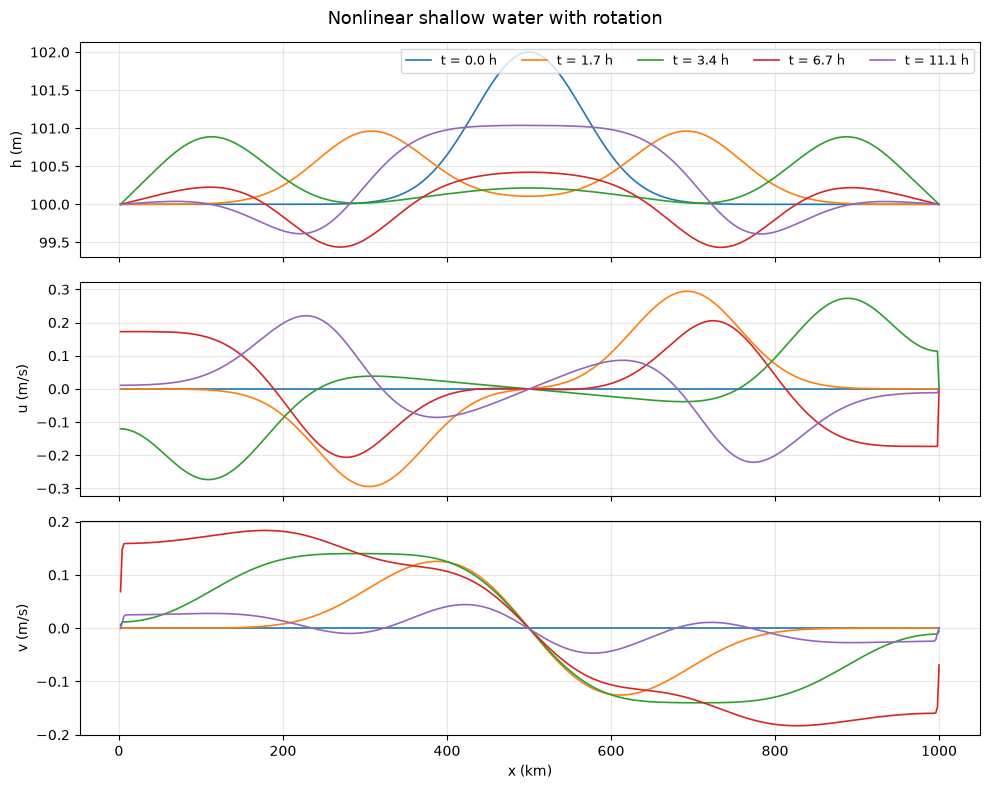

In [7]:
position_km = position[interior] / 1e3  # → (N_Ωx,)
time_hours = save_times / 3600.0  # → (N_T,)
snapshots = [0, 30, 60, 120, 199]

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fields = [solution.ys.h, solution.ys.u, solution.ys.v]
for ax, field, label in zip(axes, fields, ["h (m)", "u (m/s)", "v (m/s)"], strict=True):
    for colour, snapshot in enumerate(snapshots):
        ax.plot(
            position_km,
            field[snapshot, interior],
            lw=1.2,
            color=f"C{colour}",
            label=f"t = {float(time_hours[snapshot]):.1f} h",
        )
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=9, ncol=5)
axes[-1].set_xlabel("x (km)")
plt.suptitle("Nonlinear shallow water with rotation", fontsize=13)
plt.tight_layout()
plt.show()

:::{note} Known issue
The waves reach the periodic edge after about 4 hours, and the model handles that wrongly: it advects with closed walls, so the height stays pinned at the edge, $u$ and $v$ jump there, and the printed mass is not conserved. This is tracked in [issue #67](https://github.com/jejjohnson/sesmax/issues/67), and this page will be re-executed when it is fixed. What happens before the waves arrive at the edge is unaffected.
:::

## 5. Differentiability

`eqx.filter_grad` reaches the viscosity through a 1000 s integration of the nonlinear model, for $\mathcal{L} = \sum_n h_n^2$.

In [8]:
# today (equinox)
@eqx.filter_grad
def height_gradient(model):
    """∂ℒ/∂(parameters), for ℒ = ∑ₙ h(xₙ, 1000 s)²."""
    # today (sesmax_core, diffrax)
    window = model.integrate(initial_state, t0=0.0, t1=1000.0, dt=time_step)
    # ℒ = ∑ₙ hₙ²
    return jnp.sum(window.ys.h**2)


model_gradients = height_gradient(model)
print(f"dL/d(viscosity) = {float(model_gradients.params.lateral_viscosity):.6f}")

dL/d(viscosity) = 0.000002


## Summary

| Concept | sesmax API |
| --- | --- |
| Create the model | `NonlinearShallowWater1D.create(nx, Lx, g, f0, H0, lateral_viscosity)` |
| Initial state | `NonlinearSW1DState(h=..., u=..., v=...)` |
| Forward simulation | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Gradient with respect to the parameters | `eqx.filter_grad(loss)(model)` |

- Nonlinear terms steepen the waves, because taller parts of a wave travel faster.
- Coriolis coupling generates $v$ from $u$ through inertial oscillations.
- Viscosity keeps the fronts resolved.

**Next:** [Step 16 — 2D Geostrophic Adjustment](step16_geostrophic_adjustment.ipynb)